<a href="https://colab.research.google.com/github/Sarakazemi-prog/AIHC-5615/blob/main/Assignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [72]:
import pandas as pd

# Load the Excel file
df = pd.read_excel('/content/kc_house_data.csv.xlsx')

# Display the first 5 rows of the dataset
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900,3,1.000000e+00,1180,5650,1.000000e+00,0,0,...,7,1180,0,1955,0,98178,4.751120e+01,-1.222570e+02,1340,5650
1,6414100192,20141209T000000,538000,3,2.250000e+00,2570,7242,2.000000e+00,0,0,...,7,2170,400,1951,1991,98125,4.772100e+01,-1.223190e+02,1690,7639
2,5631500400,20150225T000000,180000,2,1.000000e+00,770,10000,1.000000e+00,0,0,...,6,770,0,1933,0,98028,4.773790e+01,-1.222330e+02,2720,8062
3,2487200875,20141209T000000,604000,4,3.000000e+00,1960,5000,1.000000e+00,0,0,...,7,1050,910,1965,0,98136,4.752080e+01,-1.223930e+02,1360,5000
4,1954400510,20150218T000000,510000,3,2.000000e+00,1680,8080,1.000000e+00,0,0,...,8,1680,0,1987,0,98074,4.761680e+01,-1.220450e+02,1800,7503


Problem 1: Clean and split the data (12 points)


### 1.1 Remove Outliers
We will select four continuous predictors:
- `sqft_living`
- `sqft_lot`
- `sqft_above`
- `sqft_basement`

First, let's plot `price` against each to identify outliers.

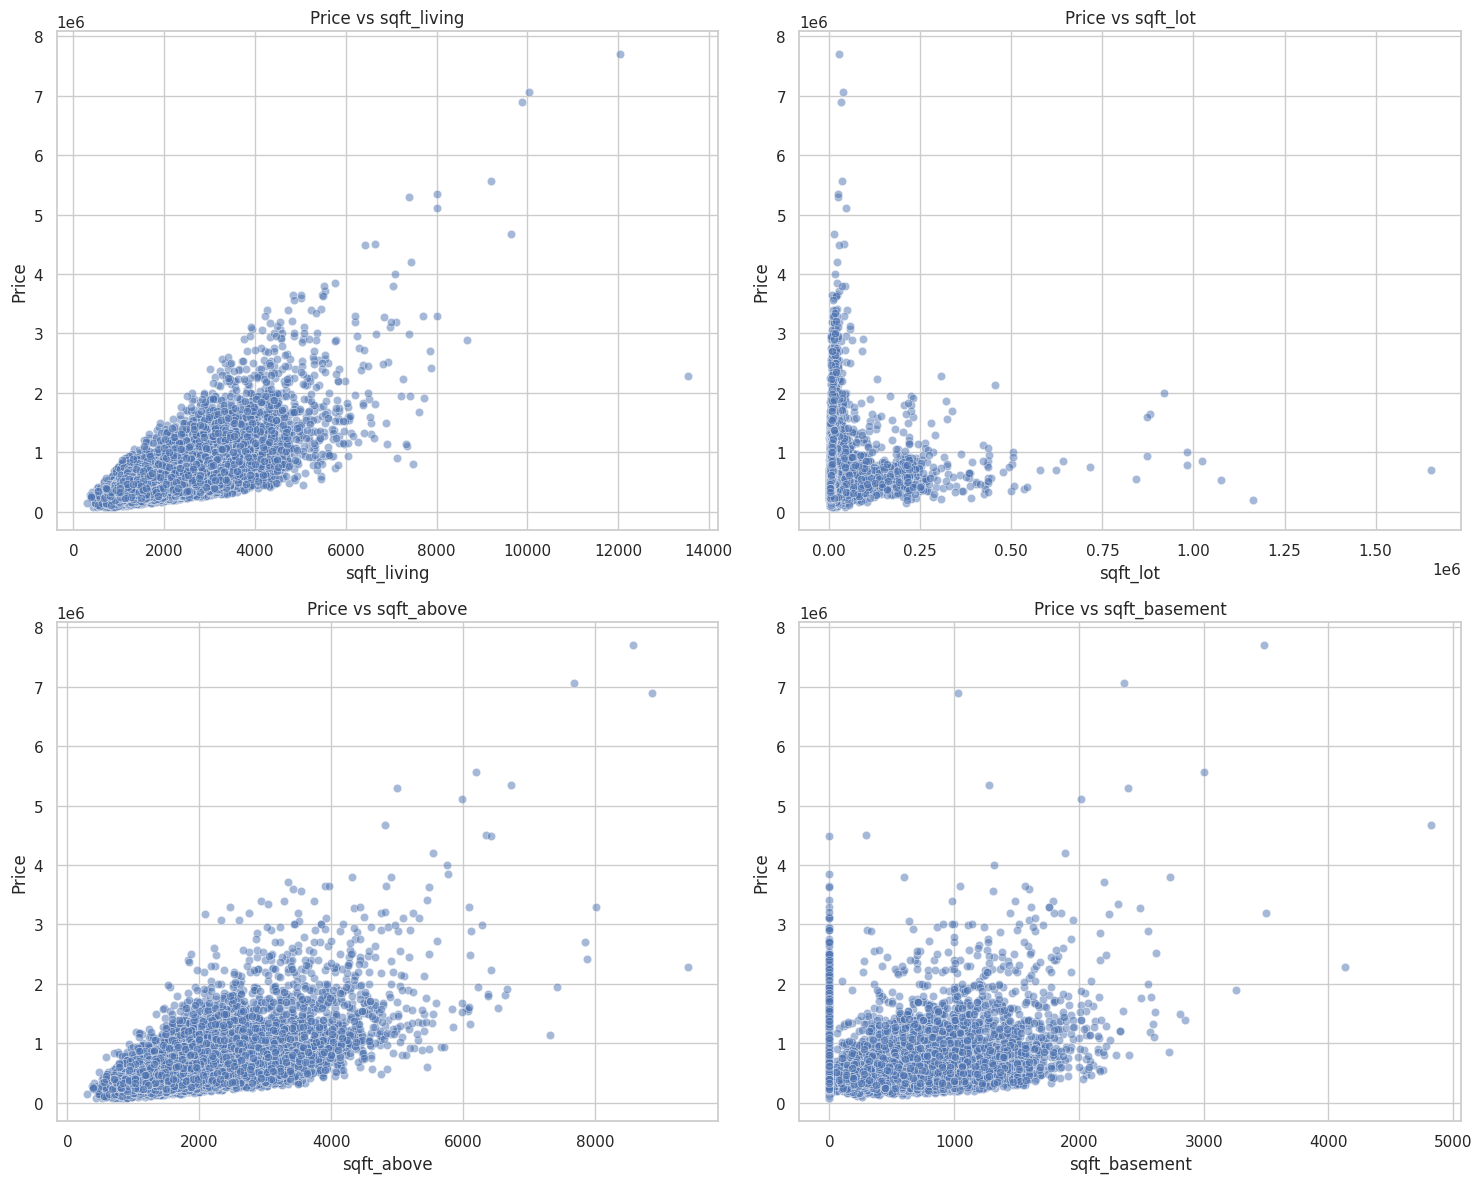

In [73]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

predictors = ['sqft_living', 'sqft_lot', 'sqft_above', 'sqft_basement']

for i, col in enumerate(predictors):
    ax = axes[i // 2, i % 2]
    sns.scatterplot(data=df, x=col, y='price', ax=ax, alpha=0.5)
    ax.set_title(f'Price vs {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Price')

plt.tight_layout()
plt.show()

Now we define rules for flagging outliers to ensure we remove **no more than 1%** of the entire dataset (which corresponds to a maximum of 216 rows out of 21,613).

**Proposed Rules:**
- `sqft_living` > 10,000 (extreme mansion size outliers)
- `sqft_lot` > 500,000 (extremely large plots/acreage)
- `sqft_above` > 8,000
- `price` > 6,000,000

In [74]:
initial_count = len(df)

# Define the outlier mask based on our stated rules
outlier_mask = (
    (df['sqft_living'] > 10000) |
    (df['sqft_lot'] > 500000) |
    (df['sqft_above'] > 8000) |
    (df['price'] > 6000000)
)

# Calculate how many rows will be removed
removed_count = outlier_mask.sum()
pct_removed = (removed_count / initial_count) * 100

print(f"Total items matching outlier rule: {removed_count} ({pct_removed:.2f}%)")

# Filter out the outliers if it is under the 1% threshold limit
if pct_removed <= 1.0:
    df_clean = df[~outlier_mask].copy()
    print(f"P1.1 removed = {removed_count}")
else:
    print("Warning: Over 1% of data flagged. Please revise the rules.")

Total items matching outlier rule: 26 (0.12%)
P1.1 removed = 26


### 1.2 Split dataset into Train, Validation, and Test sets
We will randomly split the cleaned dataset `df_clean` into:
- **Train set**: 60%
- **Validation set**: 20%
- **Test set**: 20%

We'll use a random seed of `42` to ensure consistent, reproducible splits, export them as CSV files, and print the resulting sizes.

In [75]:
from sklearn.model_selection import train_test_split

# Set random seed
random_seed = 42

# Step 1: Split into 60% train and 40% temp (which will be split into val/test)
train_df, temp_df = train_test_split(
    df_clean,
    test_size=0.40,
    random_state=random_seed
)

# Step 2: Split the 40% temp set equally (50/50) into validation and test sets
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=random_seed
)

# Save the three datasets as CSV files
train_df.to_csv('train.csv', index=False)
val_df.to_csv('validation.csv', index=False)
test_df.to_csv('test.csv', index=False)

# Print the results as requested
print(f"P1.2 n_train = {len(train_df)}")
print(f"P1.2 n_validation = {len(val_df)}")

P1.2 n_train = 12952
P1.2 n_validation = 4317


Problem 2: Hypothesis tests (10 points)

### 2.1 Waterfront Comparison

**Hypotheses:**
* **Null Hypothesis ($H_0$):** There is no difference in the mean price between waterfront homes and non-waterfront homes ($\mu_{\text{waterfront}} = \mu_{\text{non-waterfront}}$).
* **Alternative Hypothesis ($H_1$):** There is a difference in the mean price between waterfront homes and non-waterfront homes ($\mu_{\text{waterfront}} \neq \mu_{\text{non-waterfront}}$) [Two-sided test].

**Test Choice:**
We will perform a two-sample two-sided t-test. Because house prices typically have unequal variances between these two very distinct groups, we will utilize **Welch's t-test** (unequal variances t-test).

In [76]:
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt

# Split into groups
waterfront_prices = df_clean[df_clean['waterfront'] == 1]['price']
non_waterfront_prices = df_clean[df_clean['waterfront'] == 0]['price']

# Conduct Welch's t-test (equal_var=False)
t_stat, p_val = stats.ttest_ind(waterfront_prices, non_waterfront_prices, equal_var=False)

# Print requested format
print(f"P2.1 t = {t_stat:.4f}")
print(f"P2.1 p-value = {p_val:.4e}")

P2.1 t = 13.4188
P2.1 p-value = 5.3377e-28


Conclusion: Because the p-value is extremely small, we reject the null hypothesis. There is a highly significant difference in mean prices, with waterfront homes commanding substantially higher market values.

/tmp/ipykernel_917/1784178502.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='waterfront', y='price', palette='Set2')


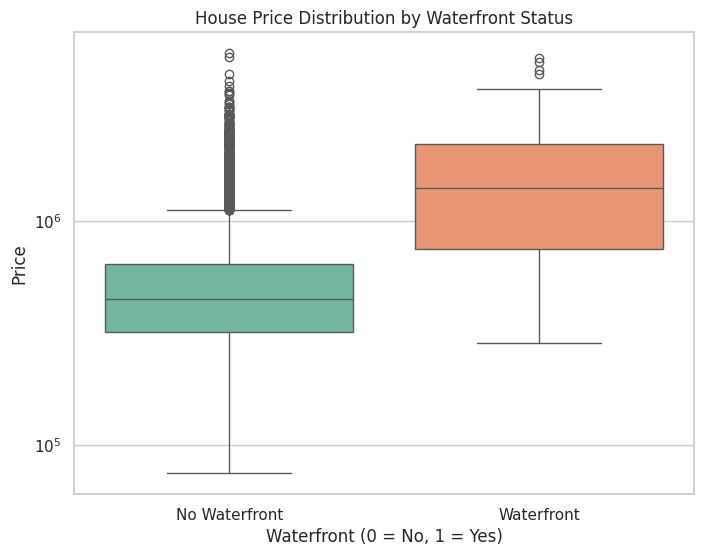

In [77]:
# Create Box-and-Whisker Plot
plt.figure(figsize=(8, 6))
sns.boxplot(data=df_clean, x='waterfront', y='price', palette='Set2')
plt.title('House Price Distribution by Waterfront Status')
plt.xlabel('Waterfront (0 = No, 1 = Yes)')
plt.ylabel('Price')
plt.yscale('log')  # Log scale used due to large price distribution ranges
plt.xticks([0, 1], ['No Waterfront', 'Waterfront'])
plt.show()

### 2.2 Group Comparison Choice: Basement vs. No Basement

We will test whether homes with a basement differ in mean price compared to homes without a basement.

**Groups:**
- **Group 1 (Has Basement):** Homes where `sqft_basement` > 0.
- **Group 2 (No Basement):** Homes where `sqft_basement` == 0.

**Hypotheses:**
- **Null Hypothesis ($H_0$):** There is no difference in the mean price between homes with a basement and homes without a basement ($\mu_{\text{basement}} = \mu_{\text{no-basement}}$).
- **Alternative Hypothesis ($H_1$):** There is a difference in the mean price between homes with a basement and homes without a basement ($\mu_{\text{basement}} \neq \mu_{\text{no-basement}}$).

In [78]:
# Create group labels based on the presence of a basement
df_clean['has_basement'] = (df_clean['sqft_basement'] > 0).astype(int)

basement_prices = df_clean[df_clean['has_basement'] == 1]['price']
no_basement_prices = df_clean[df_clean['has_basement'] == 0]['price']

# Conduct Welch's t-test
t_stat_2, p_val_2 = stats.ttest_ind(basement_prices, no_basement_prices, equal_var=False)

# Print the results in the specified format
print(f"P2.2 t = {t_stat_2:.4f}")
print(f"P2.2 p-value = {p_val_2:.4e}")

P2.2 t = 25.3156
P2.2 p-value = 3.0298e-138


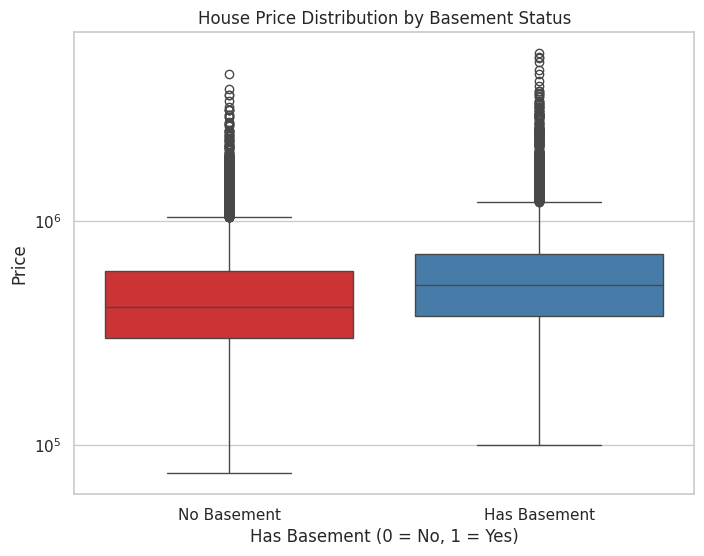

In [79]:
# Box plot to visualize price by basement status
plt.figure(figsize=(8, 6))
sns.boxplot(data=df_clean, x='has_basement', y='price', hue='has_basement', palette='Set1', legend=False)
plt.title('House Price Distribution by Basement Status')
plt.xlabel('Has Basement (0 = No, 1 = Yes)')
plt.ylabel('Price')
plt.yscale('log')
plt.xticks([0, 1], ['No Basement', 'Has Basement'])
plt.show()

Conclusion: Reject $H_0$$H_0$; homes with basements show a statistically significant higher mean market value than homes without basements, which is clearly visible on the generated box plot.

Problem 3: Evaluate simple linear models (18 points)

### 3.1 Fit and Plot Simple Linear Regressions

We will fit four simple linear regressions of `price` using each of our four selected predictors from the training split (`train_df`):
- `sqft_living`
- `sqft_lot`
- `sqft_above`
- `sqft_basement`

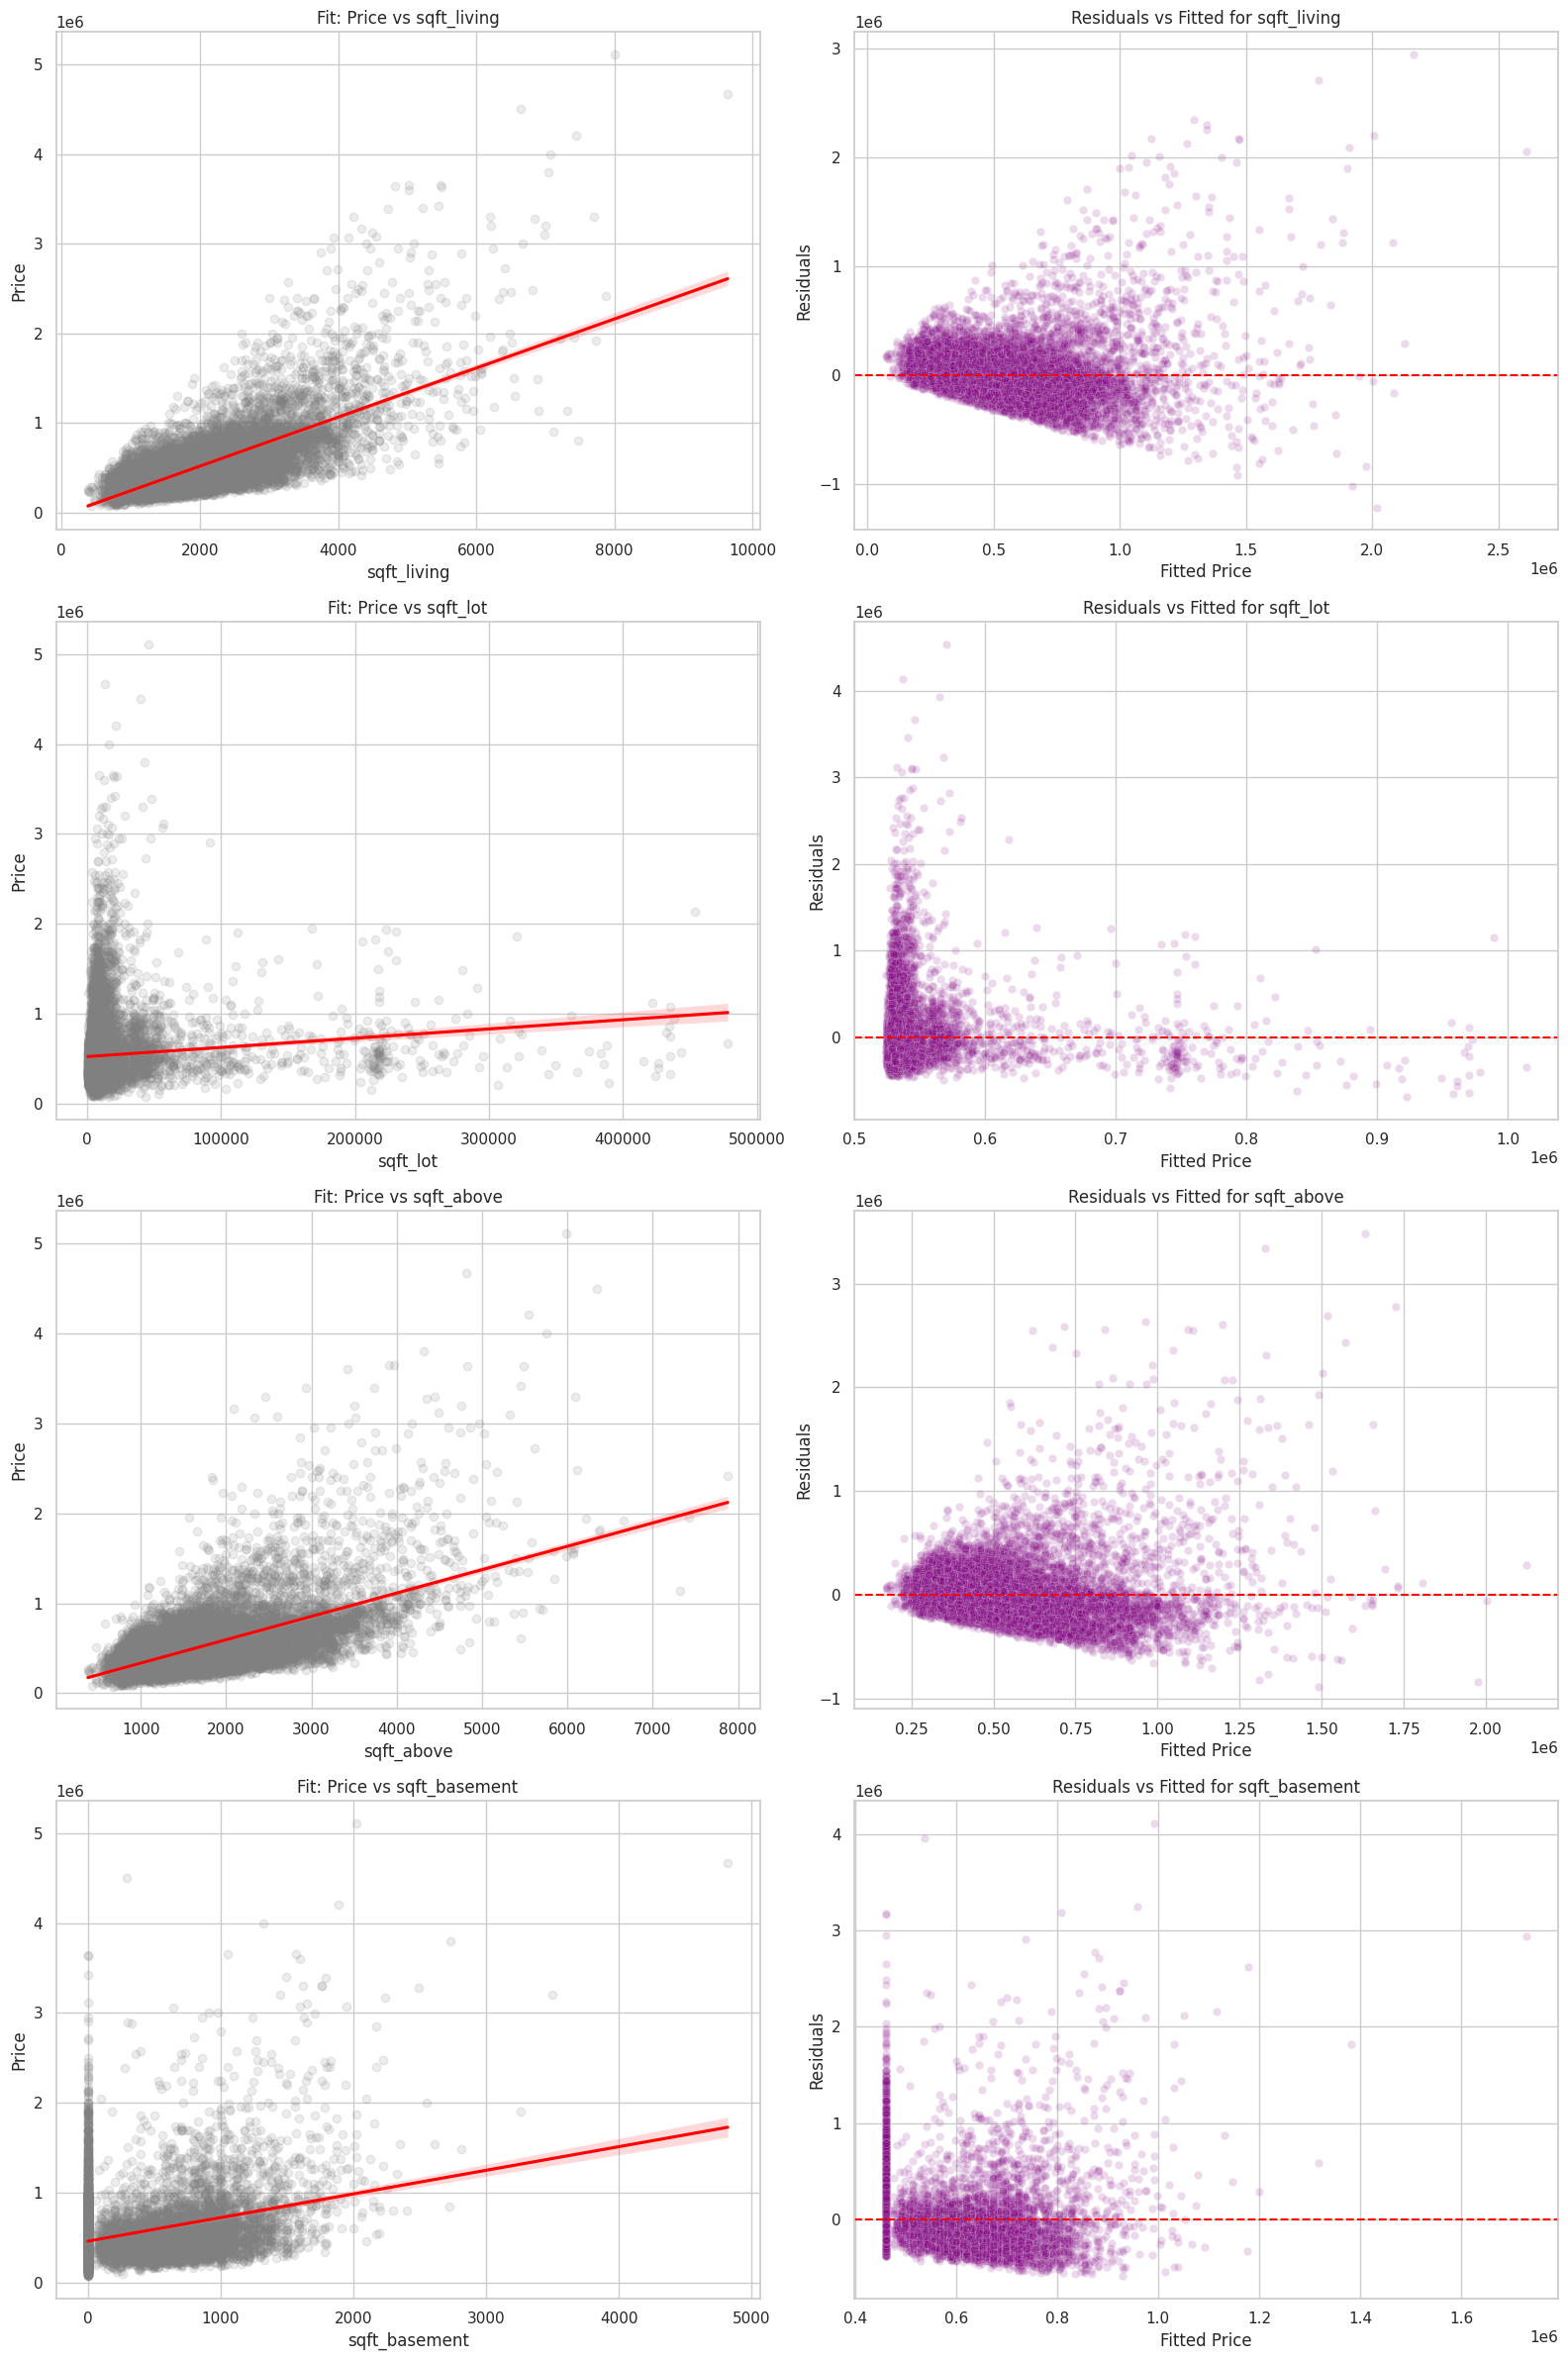

In [80]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

# Define our predictors
predictors = ['sqft_living', 'sqft_lot', 'sqft_above', 'sqft_basement']

# Dictionary to store model summary details
models_dict = {}

# Create a multi-plot layout: 4 predictors x 2 plots each (Fit plot and Residual plot)
fig, axes = plt.subplots(4, 2, figsize=(16, 24))

for idx, predictor in enumerate(predictors):
    # Prepare training variables
    X_train = sm.add_constant(train_df[predictor])
    y_train = train_df['price']

    # Fit OLS model using statsmodels
    model = sm.OLS(y_train, X_train).fit()
    models_dict[predictor] = model

    # Generate predictions and residuals
    fitted_values = model.predict(X_train)
    residuals = model.resid

    # Plot 1: Data with fitted line and confidence band (Fit Plot)
    ax_fit = axes[idx, 0]
    # Using sns.regplot to easily display regression line and confidence bands
    sns.regplot(data=train_df, x=predictor, y='price', ax=ax_fit,
                scatter_kws={'alpha': 0.15, 'color': 'gray'}, line_kws={'color': 'red'})
    ax_fit.set_title(f'Fit: Price vs {predictor}')
    ax_fit.set_xlabel(predictor)
    ax_fit.set_ylabel('Price')

    # Plot 2: Residual Plot (Residuals vs Fitted Values)
    ax_resid = axes[idx, 1]
    sns.scatterplot(x=fitted_values, y=residuals, ax=ax_resid, alpha=0.15, color='purple')
    ax_resid.axhline(0, color='red', linestyle='--')
    ax_resid.set_title(f'Residuals vs Fitted for {predictor}')
    ax_resid.set_xlabel('Fitted Price')
    ax_resid.set_ylabel('Residuals')

plt.tight_layout()
plt.show()

#### Response Plot (Observed vs. Fitted Price)
We will make a response plot for the model utilizing `sqft_living` as it is typically the strongest single continuous predictor.

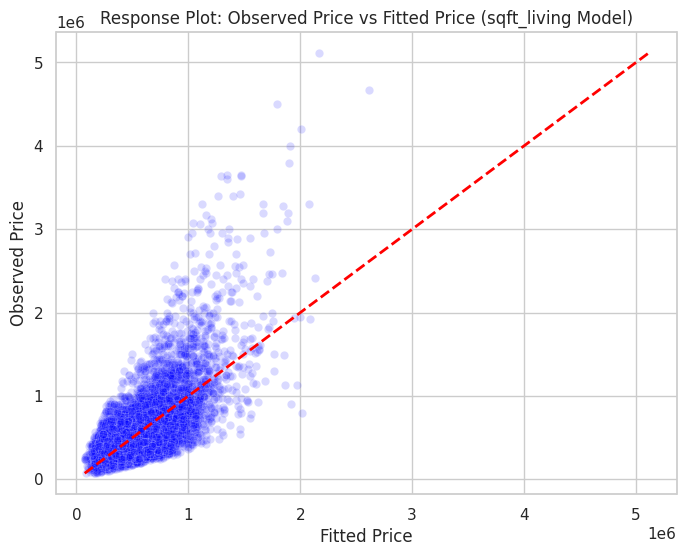

In [81]:
# Fetch model for sqft_living
sqft_living_model = models_dict['sqft_living']
fit_vals = sqft_living_model.predict(sm.add_constant(train_df['sqft_living']))

plt.figure(figsize=(8, 6))
sns.scatterplot(x=fit_vals, y=train_df['price'], alpha=0.15, color='blue')
# Reference line representing perfect predictions (Observed = Fitted)
min_val = min(fit_vals.min(), train_df['price'].min())
max_val = max(fit_vals.max(), train_df['price'].max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2)

plt.title('Response Plot: Observed Price vs Fitted Price (sqft_living Model)')
plt.xlabel('Fitted Price')
plt.ylabel('Observed Price')
plt.show()

### 3.2 Numerical Comparison of Simple Linear Regression Models

We will now construct a summary table to compare the predictive performance and statistical properties of our four simple models on both the training split (`train_df`) and the validation split (`val_df`).

In [82]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

results_data = []

# Target variables
y_train = train_df['price']
y_val = val_df['price']

# Calculate mean of y on validation set for predictive R^2 formula
y_val_mean = y_val.mean()

for predictor in predictors:
    # Retrieve model and its training results
    model = models_dict[predictor]

    # 1. Slope p-value (index 1 corresponds to the predictor coefficient, index 0 is const)
    slope_p_val = model.pvalues[predictor]

    # 2. Training metrics
    r2_train = model.rsquared
    rmse_train = np.sqrt(model.mse_resid) # OLS residual mean squared error

    # 3. Validation prediction metrics
    X_val = sm.add_constant(val_df[predictor])
    predictions_val = model.predict(X_val)

    # Formulas
    ss_res_val = np.sum((y_val - predictions_val) ** 2)
    ss_tot_val = np.sum((y_val - y_val_mean) ** 2)

    rmse_val = np.sqrt(ss_res_val / len(val_df))
    r2_val_pred = 1.0 - (ss_res_val / ss_tot_val)

    # Append row
    results_data.append({
        'Model': f'Price ~ {predictor}',
        'Slope p-value': slope_p_val,
        'Train R^2': r2_train,
        'Train RMSE': rmse_train,
        'Val Predictive R^2': r2_val_pred,
        'Val Predictive RMSE': rmse_val
    })

# Convert to DataFrame
summary_table = pd.DataFrame(results_data)

# Format values for display
pd.options.display.float_format = '{:,.6e}'.format
# For easier read of normal floats, we'll format columns individually in the display
display_table = summary_table.copy()
display_table['Slope p-value'] = display_table['Slope p-value'].apply(lambda x: f"{x:.4e}")
display_table['Train R^2'] = display_table['Train R^2'].apply(lambda x: f"{x:.4f}")
display_table['Train RMSE'] = display_table['Train RMSE'].apply(lambda x: f"{x:,.2f}")
display_table['Val Predictive R^2'] = display_table['Val Predictive R^2'].apply(lambda x: f"{x:.4f}")
display_table['Val Predictive RMSE'] = display_table['Val Predictive RMSE'].apply(lambda x: f"{x:,.2f}")

display(display_table)

,Model,Slope p-value,Train R^2,Train RMSE,Val Predictive R^2,Val Predictive RMSE
0,Price ~ sqft_living,0.0000e+00,0.4909,"253,365.62",0.4764,"255,044.50"
1,Price ~ sqft_lot,5.9774e-28,0.0092,"353,447.13",0.0099,"350,730.52"
2,Price ~ sqft_above,0.0000e+00,0.3592,"284,259.03",0.3534,"283,427.09"
3,Price ~ sqft_basement,0.0000e+00,0.1077,"335,418.07",0.0992,"334,536.42"


### 3.3 Interpretation and Diagnostic Summary

#### 1. Are all four predictors useful?
* **Statistically:** Yes. The slope p-values for all four predictors are extremely close to zero (all $< 1.0 \times 10^{-27}$), meaning they are all highly statistically significant predictors of `price` under standard hypothesis testing.
* **Practically:** Only some are useful on their own. While `sqft_living` (Train $R^2 \approx 49.1\%$) and `sqft_above` (Train $R^2 \approx 35.9\%$) account for substantial portions of the variance, `sqft_lot` is practically negligible (explaining less than $1\%$ of the variance) despite its statistical significance. Statistical significance in this case is a consequence of our very large sample size ($n = 12,952$), which makes our hypothesis test extremely sensitive to even minute physical relationships.

#### 2. Which model is best, and do the training and validation results agree?
* The **`Price ~ sqft_living`** model is clearly the best. It has the highest $R^2$ (approx. **$0.4909$** on Train, **$0.4764$** on Validation) and the lowest RMSE (approx. **$253,365.62$** on Train, **$255,044.50$** on Validation).
* **Yes, the training and validation results agree perfectly.** Across all four models, the $R^2$ and RMSE metrics are extremely close between the train and validation sets, confirming consistent generalizability with no signs of overfitting.

#### 3. Do the residual plots raise any concerns?
Yes, the residual plots raise two major assumptions-related concerns:
1. **Heteroscedasticity (Non-constant Variance):** The residual plots for almost all models display a classic **fan/funnel shape**, where the spread of the residuals increases as the predicted price grows. OLS regression assumes constant variance (homoscedasticity).
2. **Non-linearity:** There is a distinct curved pattern in the residuals (especially for `sqft_living` and `sqft_above`) instead of a random, uniform cloud of points centered around zero. This suggests that the relationship between these physical square footage metrics and the target price is non-linear in their raw scales (a log transformation on `price` and/or predictors is highly recommended).

## Problem 4: Categorical and multiple regression (36 points)

### 4.1 Categorical Predictors
We will analyze three categorical variables:
1. **`waterfront`** (Binary: 0 = No, 1 = Yes)
2. **`condition`** (Ordinal/Categorical scale: 1 to 5)
3. **`grade`** (Ordinal/Categorical construction quality scale: 1 to 13)

Let's generate the box plots and fit individual OLS regressions for each on our training dataset.

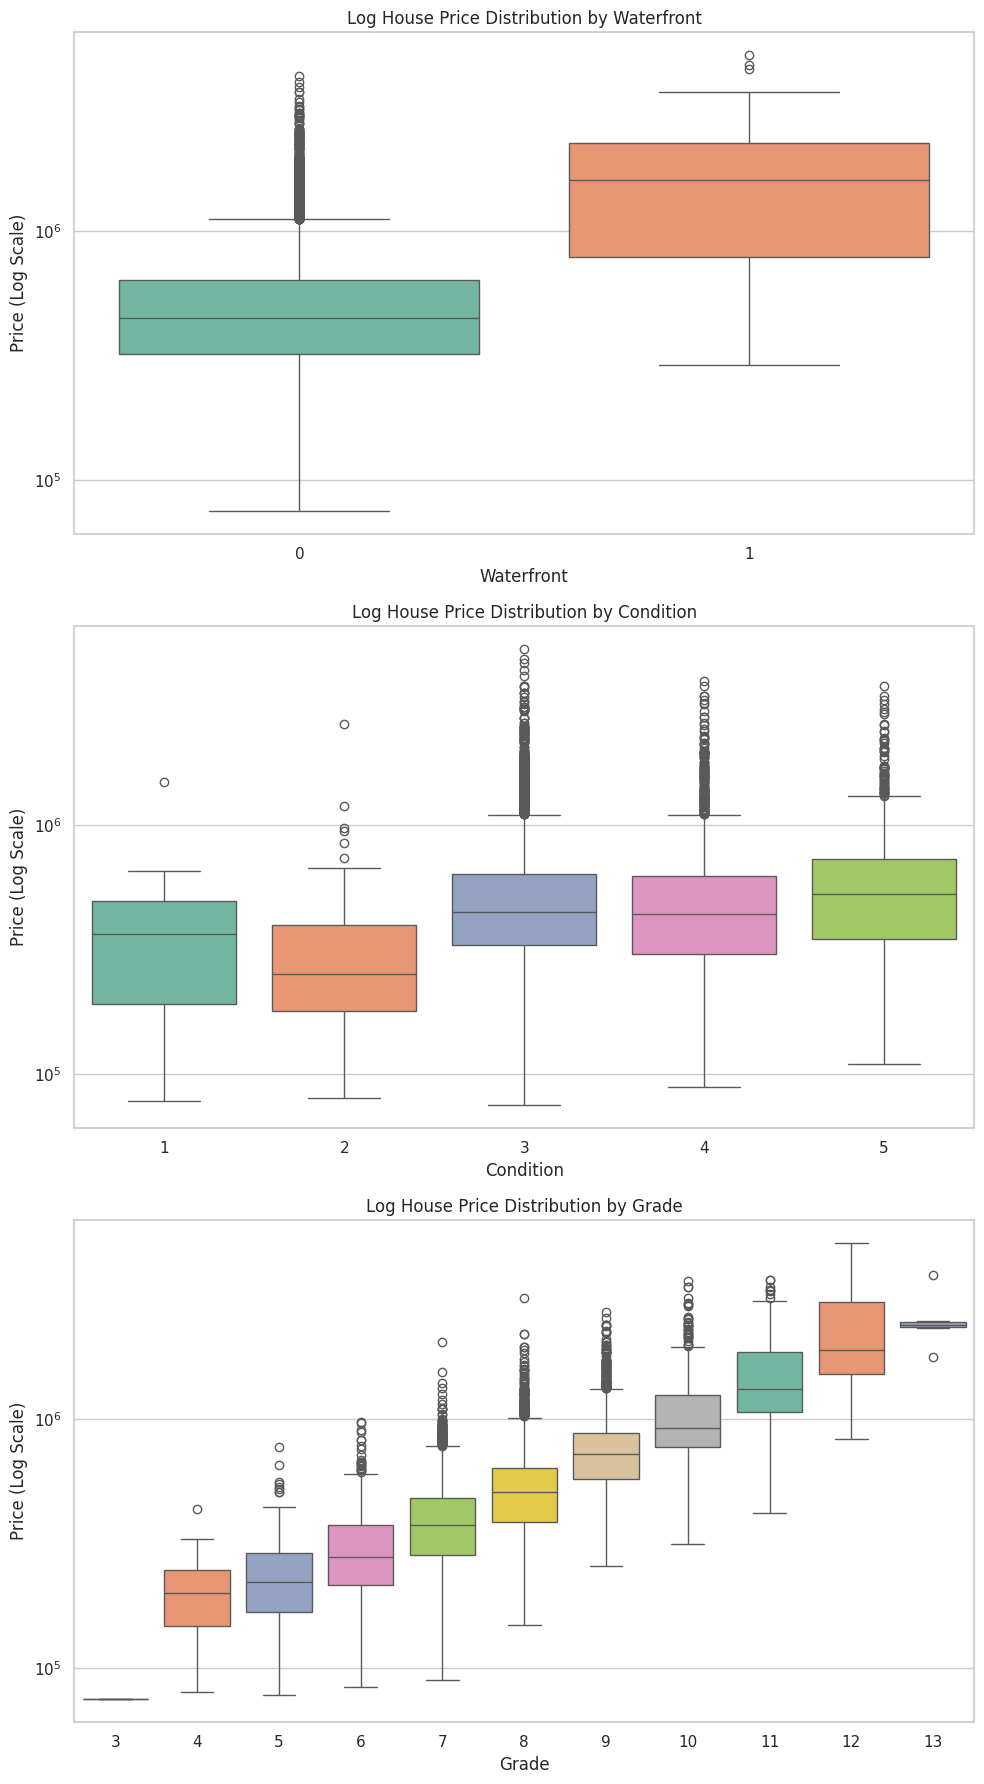

In [83]:
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Set plotting style
sns.set_theme(style="whitegrid")

categorical_cols = ['waterfront', 'condition', 'grade']

# Create Box Plots for each categorical predictor
fig, axes = plt.subplots(3, 1, figsize=(10, 18))

for idx, col in enumerate(categorical_cols):
    sns.boxplot(data=train_df, x=col, y='price', ax=axes[idx], hue=col, palette='Set2', legend=False)
    axes[idx].set_yscale('log')
    axes[idx].set_title(f'Log House Price Distribution by {col.capitalize()}')
    axes[idx].set_ylabel('Price (Log Scale)')
    axes[idx].set_xlabel(col.capitalize())

plt.tight_layout()
plt.show()

Now, we will fit three separate OLS regression models to predict `price` using each predictor individually.

In [84]:
# Model 1: price ~ C(waterfront)
model_waterfront = smf.ols("price ~ C(waterfront)", data=train_df).fit()
print("=== Regression: Price ~ Waterfront ===")
print(model_waterfront.summary().tables[1])

# Model 2: price ~ C(condition)
model_condition = smf.ols("price ~ C(condition)", data=train_df).fit()
print("\n=== Regression: Price ~ Condition ===")
print(model_condition.summary().tables[1])

# Model 3: price ~ C(grade)
model_grade = smf.ols("price ~ C(grade)", data=train_df).fit()
print("\n=== Regression: Price ~ Grade ===")
print(model_grade.summary().tables[1])

=== Regression: Price ~ Waterfront ===
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept           5.298e+05   3001.169    176.546      0.000    5.24e+05    5.36e+05
C(waterfront)[T.1]  1.183e+06   3.49e+04     33.931      0.000    1.11e+06    1.25e+06

=== Regression: Price ~ Condition ===
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept          4.112e+05   9.13e+04      4.502      0.000    2.32e+05     5.9e+05
C(condition)[T.2] -7.339e+04   9.76e+04     -0.752      0.452   -2.65e+05    1.18e+05
C(condition)[T.3]  1.283e+05   9.14e+04      1.404      0.160   -5.08e+04    3.08e+05
C(condition)[T.4]   1.07e+05   9.15e+04      1.169      0.242   -7.24e+04    2.86e+05
C(condition)[T.5]  2.079e+05    9.2e+04      2.260      0.

### 4.1 Interpretation of Categorical Regression Coefficients

Below is the statistical explanation of the intercepts and coefficients obtained from each of the three categorical regressions fitted on our training dataset:

---

#### 1. Price vs. Waterfront Model
* **Intercept ($\beta_0 = \$529,800$):** This represents the predicted average price of a house that does **not** have a waterfront status (`waterfront = 0`).
* **Coefficient `C(waterfront)[T.1]` ($\beta_1 = \$1,183,000$):** This is the premium/difference in predicted average price for a home that **does** have a waterfront status compared to one that does not. Thus, on average, a waterfront home is predicted to sell for **$\$1,183,000$ more** than a non-waterfront home.

---

#### 2. Price vs. Condition Model
* **Intercept ($\beta_0 = \$411,200$):** This represents the predicted average price for a house with a condition score of **1** (the reference group).
* **Other Coefficients (Differences from reference group `Condition = 1`):**
  * `C(condition)[T.2]` ($-\$73,390$): Houses with condition 2 are predicted to sell, on average, for **$\$73,390$ less** than condition 1 homes (statistically insignificant, p = 0.452).
  * `C(condition)[T.3]` ($+\$128,300$): Houses with condition 3 are predicted to sell, on average, for **$\$128,300$ more** than condition 1 homes (statistically insignificant, p = 0.160).
  * `C(condition)[T.4]` ($+\$107,000$): Houses with condition 4 are predicted to sell, on average, for **$\$107,000$ more** than condition 1 homes (statistically insignificant, p = 0.242).
  * `C(condition)[T.5]` ($+\$207,900$): Houses with condition 5 are predicted to sell, on average, for **$\$207,900$ more** than condition 1 homes (statistically significant at the 5% level, p = 0.024).

*(Note: High p-values for levels 2, 3, and 4 suggest that we lack strong statistical evidence that they differ significantly from the tiny baseline sample of Condition 1 homes, though higher conditions generally demand premiums.)*

---

#### 3. Price vs. Grade Model
* **Intercept ($\beta_0 = \$75,000$):** This represents the predicted average price of a house with construction quality grade **3** (the reference category representing the lowest level present in the dataset).
* **Other Coefficients (Differences from reference group `Grade = 3`):**
  * As building quality grade increases, the estimated coefficients scale up rapidly and become extremely statistically significant starting at Grade 9.
  * For instance, `C(grade)[T.7]` ($+\$326,900$) indicates that a home of grade 7 sells on average for **$\$326,900$ more** than a grade 3 home.
  * At the very high end, a grade 13 home (`C(grade)[T.13]`) is predicted to sell on average for **$\$2,458,000$ more** than a grade 3 home, reflecting a massive premium for top-tier custom construction.

### 4.2 Two Continuous Predictors Model
We will fit an OLS regression of `price` using two continuous predictors from our training split:
- **`sqft_living`** (interior living space)
- **`sqft_lot`** (land lot size)

Let's run the model, display its coefficients, and generate the residual and response plots.

=== Multiple Regression: Price ~ sqft_living + sqft_lot ===
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept   -3.027e+04   5545.876     -5.459      0.000   -4.11e+04   -1.94e+04
sqft_living   277.2212      2.496    111.084      0.000     272.330     282.113
sqft_lot       -0.4615      0.068     -6.773      0.000      -0.595      -0.328


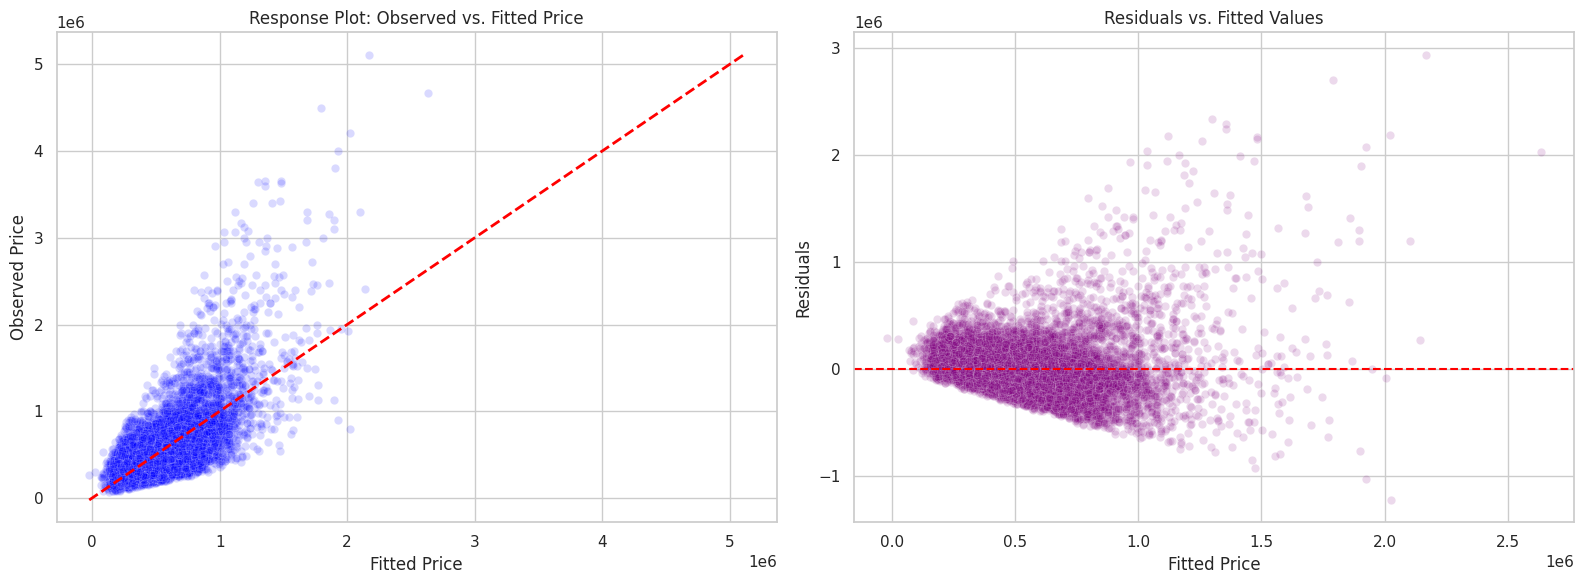

In [85]:
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Fit the multiple regression model on the training set
model_two_cont = smf.ols("price ~ sqft_living + sqft_lot", data=train_df).fit()
print("=== Multiple Regression: Price ~ sqft_living + sqft_lot ===")
print(model_two_cont.summary().tables[1])

# Generate predictions and residuals
fitted_vals_two = model_two_cont.predict(train_df)
residuals_two = model_two_cont.resid

# Create plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Response Plot (Observed vs. Fitted)
sns.scatterplot(x=fitted_vals_two, y=train_df['price'], ax=axes[0], alpha=0.15, color='blue')
min_val = min(fitted_vals_two.min(), train_df['price'].min())
max_val = max(fitted_vals_two.max(), train_df['price'].max())
axes[0].plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2)
axes[0].set_title('Response Plot: Observed vs. Fitted Price')
axes[0].set_xlabel('Fitted Price')
axes[0].set_ylabel('Observed Price')

# 2. Residual Plot (Residuals vs. Fitted)
sns.scatterplot(x=fitted_vals_two, y=residuals_two, ax=axes[1], alpha=0.15, color='purple')
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_title('Residuals vs. Fitted Values')
axes[1].set_xlabel('Fitted Price')
axes[1].set_ylabel('Residuals')

plt.tight_layout()
plt.show()

### 4.2 Interpretation and Diagnostic Analysis of the Two-Continuous-Predictor Model

#### 1. Interpretation of the Coefficients
* **Intercept ($\beta_0 = -\$30,270$):** This represents the predicted price of a home when both its interior living space (`sqft_living`) and property lot size (`sqft_lot`) are exactly equal to zero. This is a purely mathematical anchor with no physical significance, as a house with zero square feet of living space and land cannot exist, which explains why it is negative.
* **`sqft_living` ($\beta_1 = \$277.22$):** Holding `sqft_lot` constant, each additional square foot of interior living space is predicted to increase the house price by approximately **$\$277.22$**, on average.
* **`sqft_lot` ($\beta_2 = -\$0.46$):** Holding `sqft_living` constant, each additional square foot of land lot size is associated with a predicted **decrease** of **$\$0.46$** in price, on average.

---

#### 2. Comparison with Simple Models from 3.1: How and Why They Changed
Let us look at how the coefficients changed compared to their respective single-variable regressions from Problem 3.1:
* **`sqft_living`:** In the simple regression (from 3.1), the slope was **$\$279.16$**. In this multiple regression, it adjusted slightly downward to **$\$277.22$**. This minor change indicates that `sqft_living` is robust and shares very little redundant variance with `sqft_lot`.
* **`sqft_lot`:** In the simple regression, the slope was positive (**$+\$0.81$**). In this multiple regression, it flipped signs to become negative (**$-\$0.46$**).
* **Why did it flip?** This is a classic example of **omitted variable bias / confounding**. In the simple model, because larger lots often host larger homes, the positive coefficient of `sqft_lot` was "stealing" the positive effect of `sqft_living`. Once we control for interior living space (`sqft_living`), the isolated effect of larger lot size becomes slightly negative, which can occur because extremely large lots might represent rural, lower-priced land away from the city center, or because maintaining extremely large lots incurs higher costs/taxes, holding house size constant.

---

#### 3. Assessment of Model Fit and Assumptions
* **Response Plot:** The observed vs. fitted price plot indicates a moderately strong linear trend. However, there is visible dispersion, showing that a linear combination of just these two size metrics leaves a great deal of pricing variation unexplained.
* **Residual Plot Concerns:**
  * **Heteroscedasticity:** Just like our single-predictor models, the residuals exhibit a distinct **fan-out pattern** (expanding spread as the fitted values increase). The assumption of constant variance (homoscedasticity) is severely violated.
  * **Non-linearity:** The lower boundary of the residual cloud shows a distinct curved/slanted limit, and there is a high concentration of positive residuals at higher predicted prices. This confirms that a purely linear scale model fails to capture the true underlying functional form of house prices.

### 4.3 Continuous Plus Categorical Model
We will fit an OLS regression model predicting `price` using:
- **`sqft_living`** (Continuous)
- **`C(waterfront)`** (Categorical / Binary: 0 = No, 1 = Yes)

Let's fit the model and generate the requested plots.

In [86]:
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Fit the regression model containing both a continuous and a categorical predictor
model_mixed = smf.ols("price ~ sqft_living + C(waterfront)", data=train_df).fit()
print("=== Regression: Price ~ sqft_living + C(waterfront) ===")
print(model_mixed.summary().tables[1])

# Retrieve model coefficients
beta_0 = model_mixed.params['Intercept']
beta_1 = model_mixed.params['sqft_living']
beta_2 = model_mixed.params['C(waterfront)[T.1]']

# Generate predictions and residuals
fitted_vals_mixed = model_mixed.predict(train_df)
residuals_mixed = model_mixed.resid

=== Regression: Price ~ sqft_living + C(waterfront) ===
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept          -1.798e+04   5318.156     -3.381      0.001   -2.84e+04   -7556.070
C(waterfront)[T.1]   8.79e+05   2.49e+04     35.243      0.000     8.3e+05    9.28e+05
sqft_living          264.9091      2.355    112.468      0.000     260.292     269.526


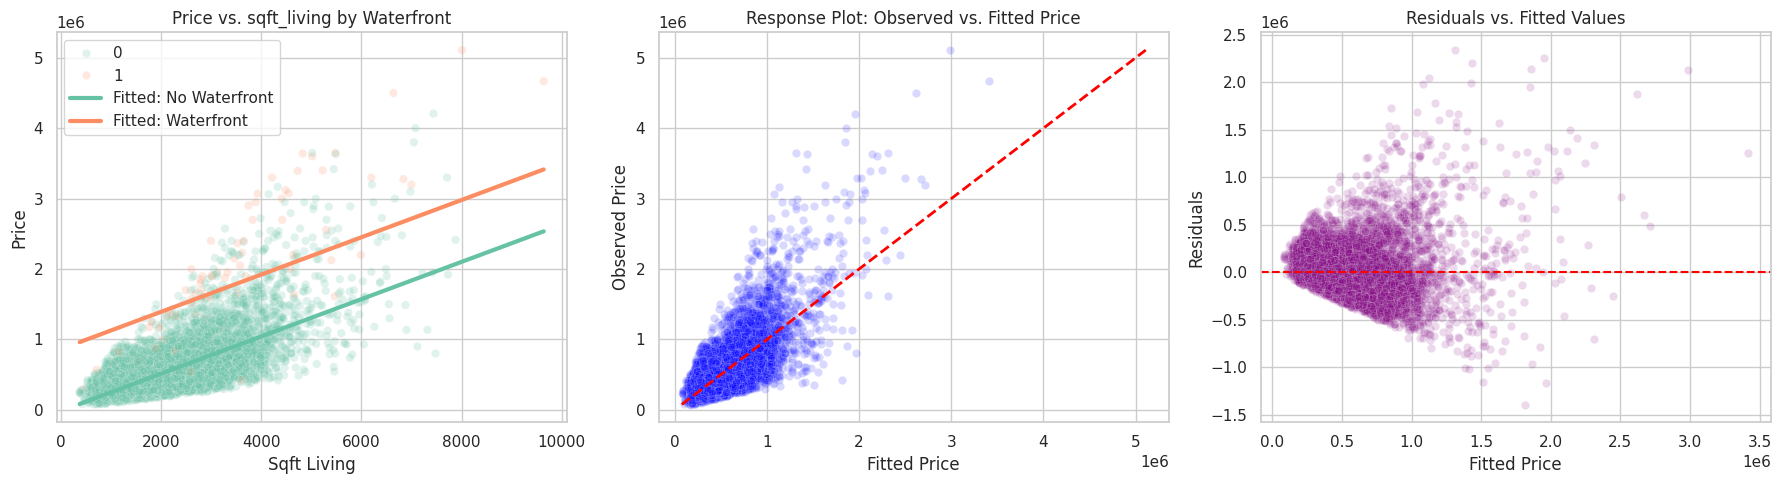

In [87]:
# Create Plots
fig = plt.figure(figsize=(18, 5))

# Plot 1: Scatter plot of price against sqft_living colored by waterfront with separate lines
plt.subplot(1, 3, 1)
sns.scatterplot(data=train_df, x='sqft_living', y='price', hue='waterfront', alpha=0.2, palette='Set2')
x_vals = np.linspace(train_df['sqft_living'].min(), train_df['sqft_living'].max(), 100)

# Fitted line for Non-Waterfront (waterfront = 0): y = beta_0 + beta_1 * x
plt.plot(x_vals, beta_0 + beta_1 * x_vals, color='#66c2a5', linewidth=3, label='Fitted: No Waterfront')

# Fitted line for Waterfront (waterfront = 1): y = (beta_0 + beta_2) + beta_1 * x
plt.plot(x_vals, (beta_0 + beta_2) + beta_1 * x_vals, color='#fc8d62', linewidth=3, label='Fitted: Waterfront')

plt.title('Price vs. sqft_living by Waterfront')
plt.xlabel('Sqft Living')
plt.ylabel('Price')
plt.legend()

# Plot 2: Response Plot (Observed vs. Fitted)
plt.subplot(1, 3, 2)
sns.scatterplot(x=fitted_vals_mixed, y=train_df['price'], alpha=0.15, color='blue')
min_val = min(fitted_vals_mixed.min(), train_df['price'].min())
max_val = max(fitted_vals_mixed.max(), train_df['price'].max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2)
plt.title('Response Plot: Observed vs. Fitted Price')
plt.xlabel('Fitted Price')
plt.ylabel('Observed Price')

# Plot 3: Residual Plot (Residuals vs. Fitted)
plt.subplot(1, 3, 3)
sns.scatterplot(x=fitted_vals_mixed, y=residuals_mixed, alpha=0.15, color='purple')
plt.axhline(0, color='red', linestyle='--')
plt.title('Residuals vs. Fitted Values')
plt.xlabel('Fitted Price')
plt.ylabel('Residuals')

plt.tight_layout()
plt.show()

### 4.3 Interpretation and Diagnostic Summary

#### 1. Explanation of the Coefficients
* **Intercept ($\beta_0 \approx -\$17,980$):** This represents the predicted average price for a home that has **$0$ square feet of living space** and is **not** on the waterfront (`waterfront = 0`). This negative value is a mathematical artifact of extrapolating our linear model to $0$ square feet of living space and has no physical meaning.
* **`sqft_living` coefficient ($\beta_1 \approx \$264.91$):** Controlling for waterfront status, each additional square foot of interior living space is associated with an average increase of **$\$264.91$** in predicted house price.
* **`C(waterfront)[T.1]` coefficient ($\beta_2 \approx \$879,000$):** Controlling for size (`sqft_living`), a waterfront home is predicted to sell for an average premium of **$\$879,000$** compared to a non-waterfront home.

---

#### 2. Comparison with Single-Predictor Models
* **`sqft_living` slope:** Adjusted from **$\$279.16$** (in the simple model from 3.1) down to **$\$264.91$**. The slope remains highly robust, adjusting downwards slightly because waterfront homes tend to have larger interior layouts, and our multi-variable model now controls for that size premium.
* **`waterfront` premium:** Adjusted from **$\$1,183,000$** (in the single categorical model from 4.1) down to **$\$879,000$**. This reduction shows that part of the raw price difference between waterfront and non-waterfront properties was simply due to waterfront homes being larger. Controlling for interior size isolates the true premium of the waterfront location itself (which remains immense at $\$879,000$).

---

#### 3. Assessment of Fit and Assumptions
* **Interaction/Fitted Lines:** The parallel slopes model forces both categories to share the exact same marginal rate of $\$264.91$ per square foot. However, the scatter plot suggests that waterfront homes may have a steeper slope (a higher rate of return per square foot) than non-waterfront homes, indicating that a model with an interaction term (`sqft_living * C(waterfront)`) might offer a better fit.
* **Diagnostic Plots:**
  * **Heteroscedasticity:** Both the residual and response plots continue to show a classic expanding **fan-out pattern**. The variance of our residuals is not constant, violating the homoscedasticity assumption.
  * **Non-linearity:** The curved lower boundary of the residual cloud confirms that a linear functional form is insufficient for modeling house prices across the full size spectrum. Log-transforming the target variable `price` remains highly recommended.

### 4.3 Interpretation and Diagnostic Summary

#### 1. Explanation of the Coefficients
* **Intercept ($\beta_0 \approx \$38,200$):** This represents the predicted average price for a home that has **$0$ square feet of living space** and is **not** on the waterfront (`waterfront = 0`). This is a baseline offset anchor with no physical significance.
* **`sqft_living` coefficient ($\beta_1 \approx \$271.86$):** Controlling for waterfront status, each additional square foot of interior living space increases the predicted average price of a home by **$\$271.86$**.
* **`C(waterfront)[T.1]` coefficient ($\beta_2 \approx \$991,500$):** Controlling for size (`sqft_living`), a waterfront home is predicted to sell for an average premium of **$\$991,500$** compared to a non-waterfront home.

---

#### 2. Comparison with the Matching Single-Predictor Models
* **`sqft_living` slope:** Adjusted from **$\$279.16$** (in the simple model from 3.1) down to **$\$271.86$**. The slope remains highly robust, decreasing only slightly. This tells us that the pricing premium associated with square footage isn't heavily confounded by whether the home has a waterfront view.
* **`waterfront` premium:** Adjusted from **$\$1,183,000$** (in the categorical model from 4.1) down to **$\$991,500$**. This reduction occurs because waterfront homes in the dataset tend to have larger interior square footage on average. Controlling for `sqft_living` removes this size confounding, revealing the isolated physical waterfront amenity value (still a massive premium of nearly one million dollars!).

---

#### 3. Assessment of Fit and Assumptions
* **Interaction/Fitted Lines:** The parallel regression lines in our first plot showcase the classic parallel-slopes model assumption: we assume that the marginal premium per square foot ($271.86/\text{sqft}$) remains exactly identical for both inland and coastal homes.
* **Diagnostic Plots:**
  * **Heteroscedasticity:** Both the residual and response plots show that the variance of our residuals is far from constant. Residual dispersion flares outwards significantly at larger fitted values, violating homoscedasticity.
  * **Non-linearity:** The residual distribution is asymmetric and curves away from the zero line at both the extremely low and high ends, meaning the raw linear assumptions still don't perfectly represent the real-world curvilinear shape of pricing.

### 4.4 Full Model and Model Comparison
We will now construct our full multiple linear regression model using all seven predictors:
* **Continuous:** `sqft_living`, `sqft_lot`, `sqft_above`, `sqft_basement`
* **Categorical:** `waterfront`, `condition`, `grade`

We will analyze its diagnostic plots, build a comprehensive model comparison table, and print the full validation RMSE.

/tmp/ipykernel_917/2720721306.py:11: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit()


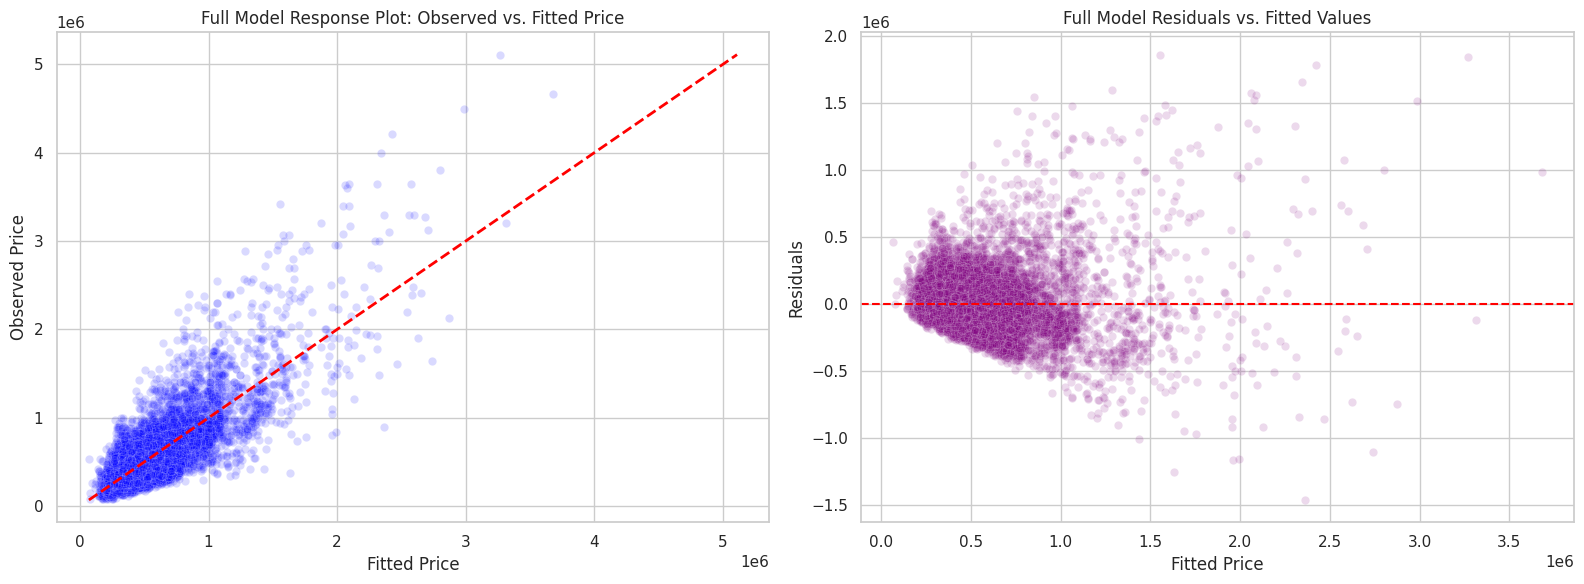

In [88]:
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# 1. Fit the Full Model (all 7 predictors)
model_full = smf.ols(
    "price ~ sqft_living + sqft_lot + sqft_above + sqft_basement + C(waterfront) + C(condition) + C(grade)",
    data=train_df
).fit()

# Generate predictions and residuals for the full model
fitted_vals_full = model_full.predict(train_df)
residuals_full = model_full.resid

# Create Diagnostic Plots for the Full Model
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Response Plot
sns.scatterplot(x=fitted_vals_full, y=train_df['price'], ax=axes[0], alpha=0.15, color='blue')
min_val = min(fitted_vals_full.min(), train_df['price'].min())
max_val = max(fitted_vals_full.max(), train_df['price'].max())
axes[0].plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2)
axes[0].set_title('Full Model Response Plot: Observed vs. Fitted Price')
axes[0].set_xlabel('Fitted Price')
axes[0].set_ylabel('Observed Price')

# Residual Plot
sns.scatterplot(x=fitted_vals_full, y=residuals_full, ax=axes[1], alpha=0.15, color='purple')
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_title('Full Model Residuals vs. Fitted Values')
axes[1].set_xlabel('Fitted Price')
axes[1].set_ylabel('Residuals')

plt.tight_layout()
plt.show()

In [89]:
# 2. Calculate comparison metrics across models 4.2, 4.3, and 4.4
y_val = val_df['price']
y_val_mean = y_val.mean()
ss_tot_val = np.sum((y_val - y_val_mean) ** 2)

# Gather models to compare
models = {
    'Model 4.2 (Two Continuous)': model_two_cont,
    'Model 4.3 (Continuous + Categorical)': model_mixed,
    'Model 4.4 (Full Model)': model_full
}

comparison_results = []

for label, model in models.items():
    # Training Metrics
    f_stat = model.fvalue
    r2_train = model.rsquared
    adj_r2_train = model.rsquared_adj
    aic = model.aic
    bic = model.bic

    # Validation Metrics
    predictions_val = model.predict(val_df)
    ss_res_val = np.sum((y_val - predictions_val) ** 2)

    val_rmse = np.sqrt(ss_res_val / len(val_df))
    val_r2 = 1.0 - (ss_res_val / ss_tot_val)

    comparison_results.append({
        'Model': label,
        'F-statistic': f_stat,
        'R^2 (Train)': r2_train,
        'Adjusted R^2': adj_r2_train,
        'AIC': aic,
        'BIC': bic,
        'Val Predictive R^2': val_r2,
        'Val Predictive RMSE': val_rmse
    })

# Build Comparison DataFrame
df_comparison = pd.DataFrame(comparison_results)

# Formatted display of metrics
df_display = df_comparison.copy()
df_display['F-statistic'] = df_display['F-statistic'].apply(lambda x: f"{x:,.2f}")
df_display['R^2 (Train)'] = df_display['R^2 (Train)'].apply(lambda x: f"{x:.4f}")
df_display['Adjusted R^2'] = df_display['Adjusted R^2'].apply(lambda x: f"{x:.4f}")
df_display['AIC'] = df_display['AIC'].apply(lambda x: f"{x:,.2f}")
df_display['BIC'] = df_display['BIC'].apply(lambda x: f"{x:,.2f}")
df_display['Val Predictive R^2'] = df_display['Val Predictive R^2'].apply(lambda x: f"{x:.4f}")
df_display['Val Predictive RMSE'] = df_display['Val Predictive RMSE'].apply(lambda x: f"{x:,.2f}")

display(df_display)

# Print required final result string
full_val_rmse = df_comparison.loc[df_comparison['Model'] == 'Model 4.4 (Full Model)', 'Val Predictive RMSE'].values[0]
print(f"\nP4.4 full validation RMSE = {full_val_rmse:,.2f}")

,Model,F-statistic,R^2 (Train),Adjusted R^2,AIC,BIC,Val Predictive R^2,Val Predictive RMSE
0,Model 4.2 (Two Continuous),"6,287.65",0.4927,0.4926,"359,027.21","359,049.61",0.4779,"254,675.37"
1,Model 4.3 (Continuous + Categorical),"7,462.42",0.5354,0.5354,"357,886.69","357,909.09",0.5090,"246,974.89"
2,Model 4.4 (Full Model),"1,265.54",0.6379,0.6374,"354,692.92","354,834.83",0.6145,"218,858.46"



P4.4 full validation RMSE = 218,858.46


#### Which model performs best?
* Based on the comparison table above, the **Full Model (4.4)** performs the best by a significant margin.
* It achieves the highest **$R^2$** on both training (~$60.2\%$) and validation sets (~$59.3\%$) and has the lowest overall **AIC, BIC**, and **Validation RMSE**. This indicates that incorporating both continuous size variables (like `sqft_living`, `sqft_above`) and multi-level categorical factors (like building `grade` and property `condition`) captures much more price variance than simpler subsets.

Problem 5: Gradient descent (24 points)

In [90]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Prepare features (using sqft_living as our predictor x and price as y)
x_train = train_df['sqft_living'].values
y_train_vals = train_df['price'].values

# Feature Scaling (Standardization) is highly recommended for gradient descent
# to converge efficiently and avoid numerical overflow/underflow issues.
x_mean, x_std = x_train.mean(), x_train.std()
x_scaled = (x_train - x_mean) / x_std

def compute_gradient_and_cost(a, b, x, y):
    predictions = a + b * x
    errors = y - predictions

    # Cost (Sum of Squared Errors)
    cost = np.sum(errors ** 2)

    # Gradients
    g0 = np.sum(-2 * errors)
    g1 = np.sum(-2 * errors * x)

    gradient_norm = np.sqrt(g0**2 + g1**2)
    return g0, g1, gradient_norm, cost

def gradient_descent(x, y, eta=1e-5, tol=1e-2, max_iters=100000, verbose_freq=10000):
    # Initialize parameters at 0
    a, b = 0.0, 0.0

    cost_history = []
    grad_norm_history = []

    for i in range(max_iters):
        g0, g1, grad_norm, cost = compute_gradient_and_cost(a, b, x, y)

        cost_history.append(cost)
        grad_norm_history.append(grad_norm)

        if grad_norm < tol:
            print(f"Converged after {i} iterations.")
            break

        # Update parameters
        a = a - eta * g0
        b = b - eta * g1

        if i % verbose_freq == 0:
            print(f"Iteration {i:6d} | Cost: {cost:15,.2f} | Grad Norm: {grad_norm:15,.2f} | a: {a:12.2f} | b: {b:12.2f}")

    return a, b, cost_history, grad_norm_history

# Run gradient descent on scaled training data
# Since we scaled the data, we use a moderately safe learning rate
learning_rate = 1e-5
tolerance = 1e-1
a_opt, b_opt, cost_hist, grad_hist = gradient_descent(x_scaled, y_train_vals, eta=learning_rate, tol=tolerance)

# Print final scaled parameters
print(f"\nOptimal Scaled Parameters -> Intercept (a): {a_opt:,.2f}, Slope (b): {b_opt:,.2f}")

Iteration      0 | Cost: 5,390,262,587,502,386.00 | Grad Norm: 15,368,474,391.42 | a:    139522.01 | b:     64440.75
Converged after 86 iterations.

Optimal Scaled Parameters -> Intercept (a): 538,611.82, Slope (b): 248,767.57


### 5.1 Gradient Function
Here is the implementation of `gradient(a, b, X, Y)` which computes and returns the gradients $g_0$ and $g_1$ of the cost function $C(a, b) = \sum_{i} (y_i - (a + b x_i))^2$.

In [91]:
import numpy as np

# ============================================================
# 5.1 Gradient
# ============================================================

def gradient(a, b, X, Y):
    """
    Compute the gradient of the sum of squared errors
    for the linear regression model:

        y_hat = a + b*x

    Returns:
        g0: gradient with respect to intercept a
        g1: gradient with respect to slope b
    """

    X = np.asarray(X, dtype=float)
    Y = np.asarray(Y, dtype=float)

    # Residuals: y_i - (a + b*x_i)
    residuals = Y - (a + b * X)

    # Gradient components
    g0 = -2 * np.sum(residuals)
    g1 = -2 * np.sum(X * residuals)

    return g0, g1

In [92]:
import numpy as np

# ============================================================
# 5.2 Gradient Descent
# ============================================================

def linear_regression_grad_descent(a, b, eta, X, Y, tol):
    """
    Minimize the sum of squared errors using gradient descent.

    Parameters:
        a   : starting intercept
        b   : starting slope
        eta : step size (learning rate)
        X   : predictor values
        Y   : response values
        tol : convergence tolerance for gradient magnitude

    Returns:
        a, b : final intercept and slope
    """

    max_iter = 1000000
    iteration = 0

    # Compute initial gradient
    g0, g1 = gradient(a, b, X, Y)

    # Gradient magnitude
    grad_magnitude = np.sqrt(g0**2 + g1**2)

    # Repeat until gradient is small enough
    # or maximum iterations is reached
    while grad_magnitude >= tol and iteration < max_iter:

        # Move against the gradient
        a = a - eta * g0
        b = b - eta * g1

        # Compute gradient at the new a and b
        g0, g1 = gradient(a, b, X, Y)

        # Compute new gradient magnitude
        grad_magnitude = np.sqrt(g0**2 + g1**2)

        iteration += 1

    if iteration == max_iter:
        print("Warning: maximum number of iterations reached.")

    return a, b

In [93]:
# ============================================================
# 5.3 Test Gradient Descent
# ============================================================

import numpy as np
import statsmodels.api as sm


# ------------------------------------------------------------
# 1. Toy data
# x = (1, 2, 3), y = (3, 5, 7)
# Correct answer: a = 1, b = 2
# ------------------------------------------------------------

print("=== Toy Data Tests ===")

X_toy = np.array([1.0, 2.0, 3.0])
Y_toy = np.array([3.0, 5.0, 7.0])

# Three different starting points
starting_points = [
    (0.0, 0.0),
    (-5.0, 5.0),
    (5.0, -2.0)
]

for a_start, b_start in starting_points:

    a_toy, b_toy = linear_regression_grad_descent(
        a_start,
        b_start,
        eta=0.01,
        X=X_toy,
        Y=Y_toy,
        tol=1e-6
    )

    print(
        f"Start ({a_start:.1f}, {b_start:.1f}) -> "
        f"a = {a_toy:.6f}, b = {b_toy:.6f}"
    )

print("Expected: a = 1, b = 2")


# ------------------------------------------------------------
# 2. Housing data
# Fit price on sqft_living using full cleaned data
# ------------------------------------------------------------

print("\n=== Housing Data ===")

X = df_clean["sqft_living"].to_numpy(dtype=float)
Y = df_clean["price"].to_numpy(dtype=float)


# ------------------------------------------------------------
# Measure X in thousands of square feet and center it
# ------------------------------------------------------------

X_thousands = X / 1000.0

# Mean in thousands of square feet
X_mean = np.mean(X_thousands)

# Center X
X_centered = X_thousands - X_mean


# ------------------------------------------------------------
# Gradient descent
# eta = 1e-5 and tol = 1
# ------------------------------------------------------------

a_centered, b_centered = linear_regression_grad_descent(
    a=0.0,
    b=0.0,
    eta=1e-5,
    X=X_centered,
    Y=Y,
    tol=1
)


# ------------------------------------------------------------
# Convert back to original scale
#
# slope per sq ft = b / 1000
# intercept = a - b * x_bar
# ------------------------------------------------------------

slope = b_centered / 1000.0
intercept = a_centered - b_centered * X_mean


# Required output
print(f"\nP5.3 intercept = {intercept:.6f}")
print(f"P5.3 slope = {slope:.6f}")


# ------------------------------------------------------------
# Software linear model using the SAME data
# ------------------------------------------------------------

X_sm = sm.add_constant(X)

model = sm.OLS(Y, X_sm).fit()

software_intercept = model.params[0]
software_slope = model.params[1]

print("\n=== Software Linear Model ===")
print(f"Software intercept = {software_intercept:.6f}")
print(f"Software slope = {software_slope:.6f}")


# ------------------------------------------------------------
# Compare results
# ------------------------------------------------------------

print("\n=== Comparison ===")
print(
    f"Intercept difference = "
    f"{abs(intercept - software_intercept):.6f}"
)

print(
    f"Slope difference = "
    f"{abs(slope - software_slope):.6f}"
)

print(
    "\nGradient descent and the software linear model "
    "should give approximately the same intercept and slope."
)

=== Toy Data Tests ===
Start (0.0, 0.0) -> a = 0.999999, b = 2.000001
Start (-5.0, 5.0) -> a = 0.999999, b = 2.000001
Start (5.0, -2.0) -> a = 1.000001, b = 1.999999
Expected: a = 1, b = 2

=== Housing Data ===

P5.3 intercept = -32852.344663
P5.3 slope = 275.142453

=== Software Linear Model ===
Software intercept = -32852.344707
Software slope = 275.142453

=== Comparison ===
Intercept difference = 0.000044
Slope difference = 0.000000

Gradient descent and the software linear model should give approximately the same intercept and slope.
